# Clase 3 — Cuánto pesa el futuro: de la cadena de Markov a Bellman

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Sutton & Barto, cap. 3 (3.3 retornos y episodios, 3.5 funciones de valor y ecuación de Bellman) y en Stanford CS234 (Brunskill), clase 1 (procesos de Markov y de recompensa de Markov).

**La pregunta de hoy:** si un premio llega en 20 pasos, ¿cuánto vale hoy? ¿Y si llega en 200?

Hoy nadie elige nada: el caminante tira un dado. Sin acciones, sin política que mejorar. Vamos a ver:

1. **El caminante sin memoria**: una cadena de Markov y su matriz $P$.
2. **Cadena + recompensa**: el proceso de recompensa de Markov de la cueva.
3. **Retorno y descuento**: cuánto pesa un premio que llega dentro de $t$ pasos.
4. **El feed, otra vez**: un feed miope contra uno de largo plazo (modelo de juguete).
5. **El valor**: el promedio de muchas caminatas.
6. **La ecuación de Bellman** y su solución directa.
7. **Iterar desde $V = 0$**: el valor se derrama desde la salida.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda menos de un minuto.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Importamos la cueva y las bibliotecas de siempre, y fijamos una semilla para que todos veamos los mismos resultados.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv

SEMILLA = 0
np.random.seed(SEMILLA)

La celda siguiente define las **herramientas** (dibujos, caminatas en paralelo y el usuario de juguete del feed). Está plegada: no hace falta leerla, solo ejecutarla.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})


# ---------- la cadena del caminante ----------
def cadena_azar(env):
    """P[s, s'] y R[s] del caminante al azar (dado de cuatro caras; si choca, se queda).
    R[s] = premio esperado del próximo paso: +1 si ese paso entra a la salida.
    La salida es absorbente y no paga más: es lo mismo que terminar la caminata."""
    return env.P.mean(axis=1), env.R.mean(axis=1)


def siguiente(env):
    """Tabla nxt[s, cara del dado] = casilla adonde lleva esa cara."""
    return np.array([[env._move(s, a)[0] for a in range(4)] for s in range(env.nS)])


def caminante(env, pasos, semilla=0, inicio=None):
    """Una caminata al azar; se corta al llegar a la salida."""
    rng = np.random.default_rng(semilla)
    s = env.start if inicio is None else inicio
    camino = [s]
    for _ in range(pasos):
        s, _ = env._move(s, int(rng.integers(4))); camino.append(s)
        if s == env.goal:
            break
    return camino


def caminatas(env, n, gamma, inicio=None, marca=None, max_pasos=3000, semilla=0):
    """n caminatas al azar en paralelo, hasta la salida (o hasta max_pasos).
    Devuelve T (paso en que llega; -1 si no llegó), G (retorno descontado = gamma^(T-1); 0 si no llegó)
    y t_marca (primer paso en que pisa la casilla 'marca'; -1 si nunca)."""
    rng = np.random.default_rng(semilla); nxt = siguiente(env)
    s = np.full(n, env.start if inicio is None else inicio)
    T = np.full(n, -1)
    tm = np.where(s == marca, 0, -1) if marca is not None else None
    for t in range(1, max_pasos + 1):
        idx = np.flatnonzero(T < 0)
        if idx.size == 0:
            break
        s[idx] = nxt[s[idx], rng.integers(4, size=idx.size)]
        T[idx[s[idx] == env.goal]] = t
        if marca is not None:
            nuevos = idx[(s[idx] == marca) & (tm[idx] < 0)]
            tm[nuevos] = t
    G = np.where(T > 0, gamma ** (T - 1.0), 0.0)
    return {"T": T, "G": G, "t_marca": tm}


def distancias(env):
    """Pasos mínimos desde cada casilla hasta la salida (búsqueda en anchura hacia atrás)."""
    d = np.full(env.nS, -1); d[env.goal] = 0; frente = [env.goal]
    while frente:
        nuevo = []
        for s in frente:
            for s2 in range(env.nS):
                if d[s2] < 0 and any(env._move(s2, a)[0] == s for a in range(4)):
                    d[s2] = d[s] + 1; nuevo.append(s2)
        frente = nuevo
    return d


def retorno(recompensas, gamma):
    """G = r_0 + gamma r_1 + gamma^2 r_2 + ..."""
    r = np.asarray(recompensas, dtype=float)
    return float(np.sum(gamma ** np.arange(len(r)) * r))


def iterar(P, R, gamma, K=None, tol=None, max_vueltas=200_000):
    """[V_0, V_1, ...] con V_0 = 0 y V_{k+1} = R + gamma P V_k.
    Para después de K vueltas, o cuando el cambio máximo de una vuelta es menor que tol."""
    V = np.zeros(len(R)); hist = [V.copy()]
    for k in range(K if K is not None else max_vueltas):
        V_nuevo = R + gamma * P @ V
        hist.append(V_nuevo.copy())
        if tol is not None and np.max(np.abs(V_nuevo - V)) < tol:
            break
        V = V_nuevo
    return hist


def log10_seguro(v, piso=1e-15):
    """log10 de un vector; donde el valor es ~0 devuelve NaN (queda negro en el dibujo)."""
    v = np.asarray(v, dtype=float)
    out = np.full_like(v, np.nan); m = v > piso
    out[m] = np.log10(v[m])
    return out


# ---------- dibujos de la cueva ----------
def plot_cave(env, values=None, ax=None, title=None, cmap="magma", clim=None, mark=None,
              numbers=False, fmt="{:.2f}", path=None):
    """env.plot + escala de color elegible, círculo opcional en una casilla y números opcionales."""
    ax = env.plot(values=values, ax=ax, title=title, cmap=cmap, path=path)
    if values is not None and clim is not None:
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    if mark is not None:
        r, c = env.free[mark]
        ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    if numbers and values is not None:
        for s, (r, c) in enumerate(env.free):
            if np.isfinite(values[s]) and s != env.goal:
                ax.text(c, r + 0.3, fmt.format(values[s]), ha="center", va="center", fontsize=7, color="w",
                        path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    return ax


def plot_row(env, values_list, titles, cmap="magma", clim=None, size=4.0, ncols=None, marks=None):
    n = len(values_list)
    ncols = n if ncols is None else ncols
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, (size * env.H / env.W + 0.6) * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    for i, ax in enumerate(axes[:n]):
        plot_cave(env, values=values_list[i], ax=ax, title=titles[i], cmap=cmap, clim=clim,
                  mark=None if marks is None else marks[i])
    plt.tight_layout(); plt.show()


def premio_en_salida(env, ax):
    gr, gc = env.free[env.goal]
    ax.text(gc, gr, "+1", ha="center", va="center", color="k", fontsize=10, weight="bold")


# ---------- el feed de juguete ----------
NSAT, SAT_INICIAL = 11, 5                      # satisfacción 0 (harto) ... 10 (encantado); arranca en 5
CLICS = {"gancho": 6.0, "útil": 3.0}           # clics esperados por día con cada regla
P_CAMBIO = 0.6                                 # prob. de que la satisfacción se mueva un nivel por día
REGLAS = ["gancho", "útil"]
COL_REGLA = {"gancho": COLORES[1], "útil": COLORES[0]}


def p_volver(sat):
    """Probabilidad de que el usuario vuelva mañana: 75 % si está harto, 99 % si está encantado."""
    return 0.75 + 0.24 * np.asarray(sat) / (NSAT - 1)


def cadena_feed(regla):
    """Con una regla fija, el usuario es una cadena de Markov con recompensa (sin acciones).
    Estados 0..10 = satisfacción; 11 = se fue (absorbente). R[s] = clics del día."""
    nS, FUERA = NSAT + 1, NSAT
    paso = -1 if regla == "gancho" else +1
    P = np.zeros((nS, nS)); R = np.zeros(nS)
    for s in range(NSAT):
        R[s] = CLICS[regla]
        for s2, p in [(int(np.clip(s + paso, 0, NSAT - 1)), P_CAMBIO), (s, 1 - P_CAMBIO)]:
            P[s, s2] += p * p_volver(s2)
            P[s, FUERA] += p * (1 - p_volver(s2))
    P[FUERA, FUERA] = 1
    return P, R


def clics_esperados(regla, dias):
    """Clics esperados en cada día t = 0, 1, ...: se empuja la nube de usuarios con p_{t+1} = p_t P."""
    P, R = cadena_feed(regla)
    p = np.zeros(NSAT + 1); p[SAT_INICIAL] = 1.0
    out = []
    for _ in range(dias):
        out.append(p @ R); p = p @ P
    return np.array(out)


def retorno_regla(regla, gamma, dias=3000):
    """Retorno descontado esperado de un usuario nuevo bajo la regla: sum_t gamma^t E[clics_t]."""
    return retorno(clics_esperados(regla, dias), gamma)


def simular_usuarios(regla, n=5000, dias=90, semilla=0):
    rng = np.random.default_rng(semilla)
    s = np.full(n, SAT_INICIAL); activo = np.ones(n, bool)
    paso = -1 if regla == "gancho" else +1
    activos, clics = [], []
    for _ in range(dias):
        c = np.where(activo, rng.poisson(CLICS[regla], size=n), 0)
        activos.append(activo.mean()); clics.append(c.mean())
        cambia = rng.random(n) < P_CAMBIO
        s = np.clip(s + np.where(cambia, paso, 0), 0, NSAT - 1)
        activo &= rng.random(n) < p_volver(s)
    return np.array(activos), np.array(clics)


def mostrar_usuario():
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
    s = np.arange(NSAT)
    axs[0].plot(s, 100 * p_volver(s), "o-", color=COLORES[2])
    axs[0].set_xlabel("satisfacción del usuario (oculta)"); axs[0].set_ylabel("% que vuelve mañana")
    axs[0].set_title("Lo que el feed no ve: la satisfacción decide si vuelve")
    bars = axs[1].bar(["gancho (clickbait)", "útil (sus intereses)"], [CLICS[r] for r in REGLAS],
                      color=[COL_REGLA[r] for r in REGLAS], width=0.5)
    axs[1].bar_label(bars, labels=[f"{CLICS['gancho']:g} clics hoy\nsatisfacción ↓",
                                   f"{CLICS['útil']:g} clics hoy\nsatisfacción ↑"], padding=3)
    axs[1].set_ylim(0, max(CLICS.values()) * 1.6); axs[1].set_title("Lo que el feed sí ve: clics de hoy")
    axs[1].grid(axis="x", visible=False)
    plt.suptitle("Modelo de juguete (números inventados)", fontsize=10, color="#777", y=1.0)
    plt.tight_layout(); plt.show()


def comparar_reglas(dias=90):
    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    res = {}
    for regla in REGLAS:
        act, cl = simular_usuarios(regla, dias=dias)
        res[regla] = (act, cl)
        nombre = f"siempre {regla}"
        axs[0].plot(cl, color=COL_REGLA[regla], label=nombre)
        axs[1].plot(100 * act, color=COL_REGLA[regla], label=nombre)
        axs[2].plot(np.cumsum(cl), color=COL_REGLA[regla], label=nombre)
    axs[0].set_title("Clics por usuario, día por día"); axs[0].set_xlabel("día")
    axs[1].set_title("% de usuarios que siguen volviendo"); axs[1].set_xlabel("día")
    axs[2].set_title("Clics acumulados por usuario"); axs[2].set_xlabel("día")
    for ax in axs:
        ax.legend(frameon=False)
    plt.suptitle("5000 usuarios de juguete durante 90 días", fontsize=10, color="#777", y=1.0)
    plt.tight_layout(); plt.show()
    cruce = int(np.argmax(np.cumsum(res["útil"][1]) > np.cumsum(res["gancho"][1])))
    for regla, (act, cl) in res.items():
        print(f"siempre {regla:7s} clics día 1: {cl[0]:4.2f} · activos el día 30: {100 * act[30]:5.1f} % · "
              f"clics en {dias} días: {cl.sum():6.1f}")
    print(f"Los clics acumulados de 'útil' pasan a los de 'gancho' el día {cruce + 1}.")
    return res


def retorno_vs_gamma(gamma_marcado=None):
    gs = np.linspace(0, 0.99, 100)
    G = {r: np.array([retorno_regla(r, g) for g in gs]) for r in REGLAS}
    lo, hi = gs[np.argmax(G["útil"] > G["gancho"]) - 1], gs[np.argmax(G["útil"] > G["gancho"])]
    for _ in range(40):                        # bisección: dónde se cruzan exactamente
        m = (lo + hi) / 2
        lo, hi = (m, hi) if retorno_regla("útil", m) < retorno_regla("gancho", m) else (lo, m)
    cruce = (lo + hi) / 2
    fig, ax = plt.subplots(figsize=(8, 4))
    for r in REGLAS:
        ax.semilogy(gs, G[r], color=COL_REGLA[r], label=f"siempre {r}")
    ax.axvline(cruce, color="gray", ls="--", lw=1)
    ax.text(cruce - 0.01, ax.get_ylim()[1] * 0.5, f"cruce: γ ≈ {cruce:.3f}", color="gray", fontsize=9, ha="right")
    if gamma_marcado is not None:
        ax.axvline(gamma_marcado, color="k", lw=1, alpha=0.5)
    ax.set_xlabel("γ del feed"); ax.set_ylabel("retorno esperado G (clics, escala log)")
    ax.set_title("Retorno descontado de cada regla según γ (modelo de juguete)")
    ax.legend(frameon=False); plt.tight_layout(); plt.show()
    return cruce


def feed_con_gamma(gamma):
    """El feed con descuento gamma elige la regla de mayor retorno descontado."""
    G = {r: retorno_regla(r, gamma) for r in REGLAS}
    elige = max(G, key=G.get)
    print(f"γ = {gamma:<5g} G(gancho) = {G['gancho']:7.2f}   G(útil) = {G['útil']:7.2f}   -> el feed elige: {elige}")
    return elige

## 1. El caminante sin memoria: $P$ y la nube de probabilidad

Un caminante tira un **dado de cuatro caras** en cada paso (↑ → ↓ ←); si choca contra una pared, se queda donde está. Adónde va **depende solo de dónde está ahora**, no de cómo llegó: es el supuesto de Markov de la clase 2. Un proceso así, sin acciones ni recompensas, se llama **cadena de Markov** (*Markov chain*).

Todo lo que hace el caminante entra en una tabla: la **matriz de transición** $P$, con una fila por casilla de partida y una columna por casilla de llegada:

$$P[s, s'] = p(s_{t+1} = s' \mid s_t = s)$$

### Paso 1 — La tabla y una caminata

Miremos $P$ como imagen y, al lado, una caminata de 60 pasos.

casillas: 60   P: (60, 60)   cada fila suma 1: True   fracción de ceros: 0.947


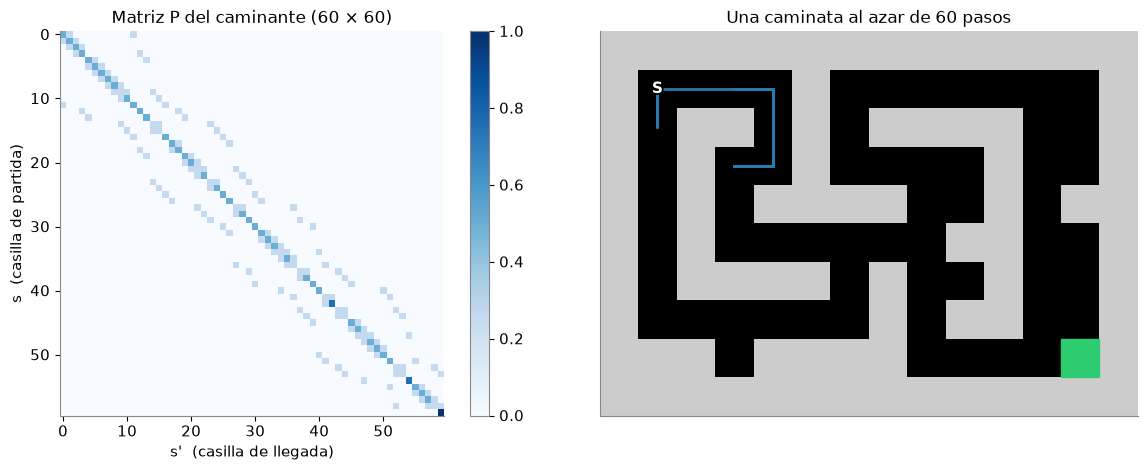

In [4]:
env = CaveEnv()
P, R = cadena_azar(env)                    # P[s, s'] (60 x 60) y R[s] (lo usamos en la sección 2)
print("casillas:", env.nS, "  P:", P.shape, "  cada fila suma 1:", np.allclose(P.sum(axis=1), 1),
      "  fracción de ceros:", round(float(np.mean(P == 0)), 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
im = ax[0].imshow(P, cmap="Blues", vmin=0, vmax=1)
ax[0].set_title("Matriz P del caminante (60 × 60)"); ax[0].grid(False)
ax[0].set_xlabel("s'  (casilla de llegada)"); ax[0].set_ylabel("s  (casilla de partida)")
plt.colorbar(im, ax=ax[0], fraction=0.046)
plot_cave(env, path=caminante(env, 60, semilla=3), ax=ax[1], title="Una caminata al azar de 60 pasos")
plt.tight_layout(); plt.show()

Casi toda la tabla es cero: desde una casilla solo se llega a sus vecinas o a ella misma (la diagonal es *chocar y quedarse*). La caminata vuelve una y otra vez sobre sus pasos: **no recuerda nada**.

### Paso 2 — Leer una fila

Una fila de $P$ es una casilla de partida. Dibujemos dos filas sobre la cueva: la del inicio **S** (arriba y a la izquierda hay pared) y la de un cruce en el medio de la cueva, en la fila 5, columna 6 (solo arriba hay pared).

Fila de P de la casilla (1, 1):
   -> (1, 1):  0.50  (se queda: choca)
   -> (1, 2):  0.25
   -> (2, 1):  0.25
   suma de la fila: 1.00
Fila de P de la casilla (5, 6):
   -> (5, 5):  0.25
   -> (5, 6):  0.25  (se queda: choca)
   -> (5, 7):  0.25
   -> (6, 6):  0.25
   suma de la fila: 1.00


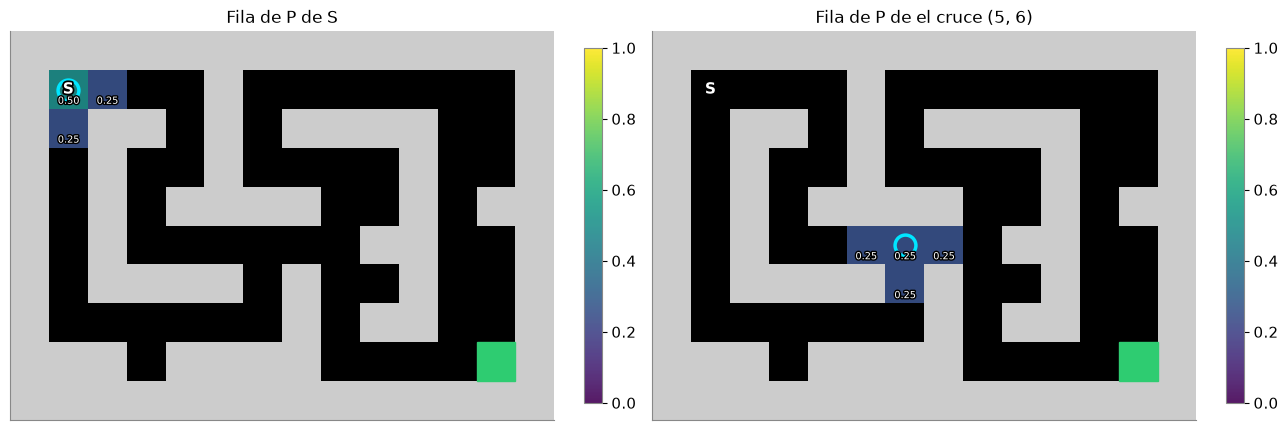

In [5]:
cruce = env.pos2s[(5, 6)]
for s in [env.start, cruce]:
    print(f"Fila de P de la casilla {env.free[s]}:")
    for s2 in np.flatnonzero(P[s]):
        nota = "  (se queda: choca)" if s2 == s else ""
        print(f"   -> {env.free[s2]}:  {P[s, s2]:.2f}{nota}")
    print(f"   suma de la fila: {P[s].sum():.2f}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, s, nombre in [(axs[0], env.start, "S"), (axs[1], cruce, "el cruce (5, 6)")]:
    plot_cave(env, values=np.where(P[s] > 0, P[s], np.nan), ax=ax, cmap="viridis", clim=(0, 1),
              mark=s, numbers=True, title=f"Fila de P de {nombre}")
plt.tight_layout(); plt.show()

Desde S, dos caras del dado chocan (↑ y ←): el caminante se queda con probabilidad $2/4 = 0{,}5$, y va a cada vecina con $1/4$. En el cruce solo choca una cara, así que se queda con $1/4$. Cada fila suma 1: a algún lugar hay que llegar.

### Paso 3 — La nube de probabilidad

En vez de un caminante, pensemos en **todos los caminantes posibles a la vez**. Si $p_t$ es la probabilidad de estar en cada casilla en el paso $t$ (un vector fila), un paso de la cadena es multiplicar por la tabla:

$$p_{t+1} = p_t\, P$$

Arrancamos con toda la nube en S. En la cadena, la salida es **absorbente**: el que llega se queda ahí. Pintamos $\log_{10} p_t$ (negro = probabilidad menor que $10^{-4}$; la salida siempre se pinta de verde, y su probabilidad va en el título).

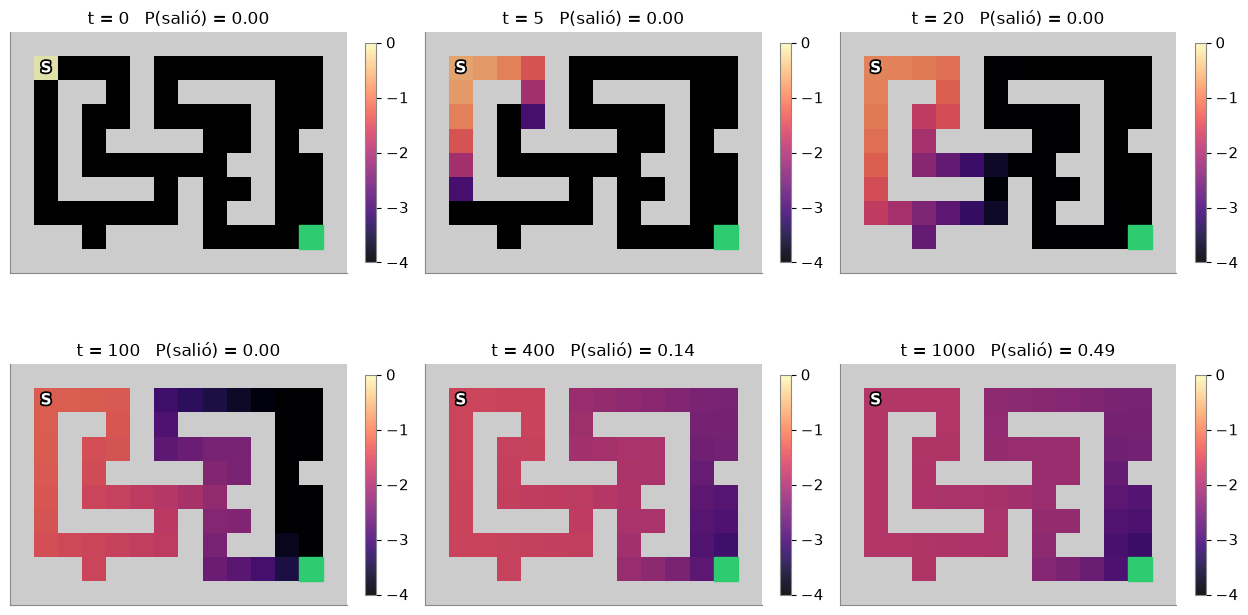

La mitad de la nube llegó a la salida en el paso 1022 (el camino más corto tiene 20 pasos).


In [6]:
p = np.zeros(env.nS); p[env.start] = 1.0
historia = [p.copy()]
for t in range(5000):
    p = p @ P; historia.append(p.copy())
historia = np.array(historia)

ts = [0, 5, 20, 100, 400, 1000]
plot_row(env, [log10_seguro(historia[t]) for t in ts],
         [f"t = {t}   P(salió) = {historia[t, env.goal]:.2f}" for t in ts],
         cmap="magma", clim=(-4, 0), size=4.2, ncols=3)
t_mitad = int(np.argmax(historia[:, env.goal] >= 0.5))
print(f"La mitad de la nube llegó a la salida en el paso {t_mitad} (el camino más corto tiene 20 pasos).")

La nube se desparrama por la cueva y se junta en la salida **muy de a poco**: el camino más corto tiene 20 pasos, pero la mitad de la nube tarda más de mil. Un caminante sin memoria y sin objetivo tarda muchísimo en dar con un premio lejano: es la recompensa escasa y demorada de la clase 2.

## 2. Cadena + recompensa: el MRP de la cueva

Le ponemos un premio a la cadena: **+1 en el paso que entra a la salida**, 0 en todos los demás. Una cadena de Markov con recompensa se llama **proceso de recompensa de Markov** (*Markov reward process*, MRP). El caminante sigue sin elegir nada: sigue tirando el dado.

Para cada casilla anotamos $R(s)$: el premio que **espera** cobrar en el próximo paso si está en $s$. Como el premio se cobra al entrar a la salida, $R(s)$ solo es distinto de 0 en las casillas pegadas a la salida.

**Cómo tratamos la salida (en toda la clase):** al llegar, se cobra el +1 y la caminata **termina**. En la tabla eso se escribe así: la salida es absorbente ($P[\text{salida}, \text{salida}] = 1$) y no paga más ($R(\text{salida}) = 0$). Quedarse para siempre sin cobrar nada es lo mismo que terminar. Por eso, más adelante, el valor de la salida misma va a ser 0: ahí ya no queda nada por cobrar.

R(7, 12) = 0.25   (una de sus cuatro caras entra a la salida)
R(8, 11) = 0.25   (una de sus cuatro caras entra a la salida)
R(salida) = 0,  P[salida, salida] = 1


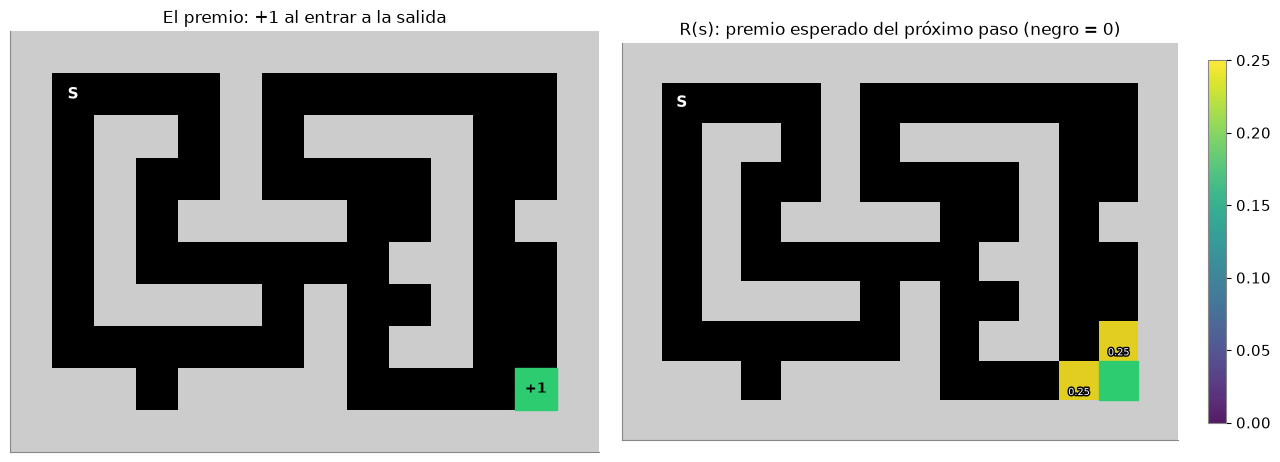

In [7]:
for s in np.flatnonzero(R):
    print(f"R{env.free[s]} = {R[s]:.2f}   (una de sus cuatro caras entra a la salida)")
print(f"R(salida) = {R[env.goal]:.0f},  P[salida, salida] = {P[env.goal, env.goal]:.0f}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
ax = plot_cave(env, ax=axs[0], title="El premio: +1 al entrar a la salida")
premio_en_salida(env, ax)
plot_cave(env, values=np.where(R > 0, R, np.nan), ax=axs[1], cmap="viridis", clim=(0, 0.25), numbers=True,
          title="R(s): premio esperado del próximo paso (negro = 0)")
plt.tight_layout(); plt.show()

Solo dos casillas tienen $R(s) = 0{,}25$: la de arriba y la de la izquierda de la salida, desde donde una de las cuatro caras del dado entra. Todo lo demás vale 0 **ahora**. La pregunta de la clase es cuánto vale **contando el futuro**.

## 3. Retorno y descuento: $\gamma^t$ y el retorno de una partida

Lo que cuenta no es el premio de este paso sino la suma de todos los que vienen: el **retorno** (*return*). Con un **factor de descuento** (*discount factor*) $\gamma$ entre 0 y 1, un premio que llega $t$ pasos más tarde pesa $\gamma^t$:

$$G_t = r_t + \gamma\, r_{t+1} + \gamma^2 r_{t+2} + \dots$$

### Paso 1 — Cuánto pesa un premio lejano

Dibujemos el peso $\gamma^t$ para tres valores de $\gamma$. La línea punteada marca $t = 19$: el premio del paso 20 (el primer paso no se descuenta, así que el vigésimo pesa $\gamma^{19}$).

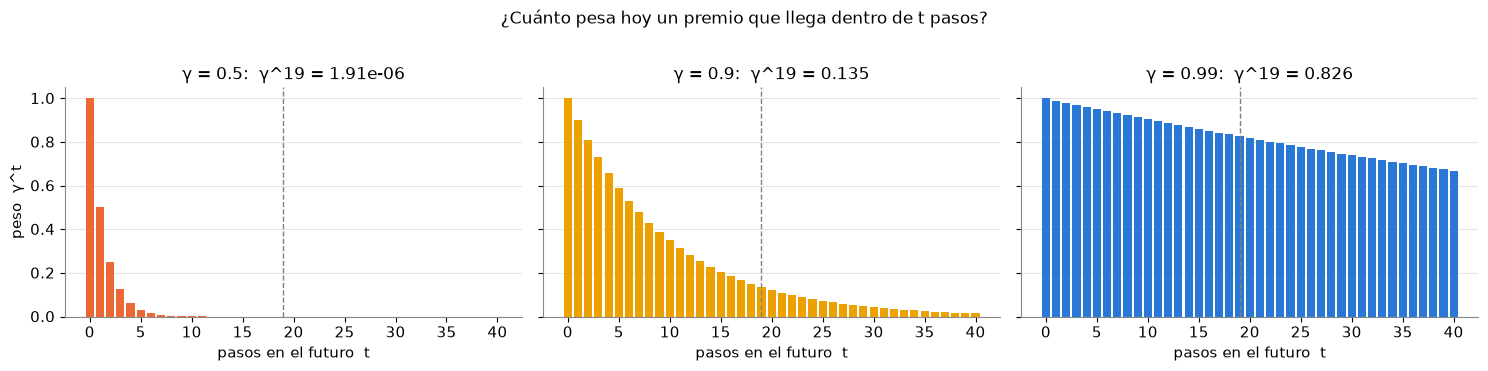

    t      γ = 0.5     γ = 0.9    γ = 0.99
    1          0.5         0.9        0.99
    5       0.0312        0.59       0.951
   10     0.000977       0.349       0.904
   19     1.91e-06       0.135       0.826
   50     8.88e-16     0.00515       0.605
  100     7.89e-31    2.66e-05       0.366
  199     1.24e-60    7.84e-10       0.135


In [8]:
t = np.arange(0, 41)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, g, col in zip(axs, [0.5, 0.9, 0.99], [COLORES[1], COLORES[3], COLORES[0]]):
    ax.bar(t, g ** t, color=col, width=0.8)
    ax.axvline(19, color="gray", ls="--", lw=1)
    ax.set_title(f"γ = {g}:  γ^19 = {g ** 19:.3g}"); ax.set_xlabel("pasos en el futuro  t")
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("peso  γ^t")
plt.suptitle("¿Cuánto pesa hoy un premio que llega dentro de t pasos?", y=1.02)
plt.tight_layout(); plt.show()

print(f"{'t':>5} " + "".join(f"{'γ = ' + str(g):>12}" for g in [0.5, 0.9, 0.99]))
for tt in [1, 5, 10, 19, 50, 100, 199]:
    print(f"{tt:>5} " + "".join(f"{g ** tt:>12.3g}" for g in [0.5, 0.9, 0.99]))

Respuesta a la pregunta de la clase: con $\gamma = 0{,}9$, el premio del paso 20 vale hoy $0{,}9^{19} \approx 0{,}135$ y el del paso 200 vale $0{,}9^{199} \approx 8 \times 10^{-10}$: prácticamente nada. Con $\gamma = 0{,}99$, el del paso 20 vale $0{,}83$ (casi lo mismo que uno inmediato) y el del paso 200, $0{,}135$. Con $\gamma = 0{,}5$, ni el del paso 20 cuenta. Y con $\gamma = 0$ solo cuenta lo inmediato: $0^t = 0$ para todo $t \geq 1$.

### Paso 2 — El retorno de una partida

Tomemos una caminata del caminante que llegue a la salida en menos de 150 pasos (buscamos la primera semilla que lo logra: la mayoría tarda mucho más). Sus recompensas son todas 0 salvo la última, que es +1. Calculemos su retorno con la fórmula para varios $\gamma$.

semilla 21: llega en T = 146 pasos;  recompensas = [0, 0, ..., 0, 1] (146 números)
  γ = 0     G_0 = 0    (= γ^(T-1) = 0)
  γ = 0.5   G_0 = 2.242e-44    (= γ^(T-1) = 2.242e-44)
  γ = 0.9   G_0 = 2.318e-07    (= γ^(T-1) = 2.318e-07)
  γ = 0.99  G_0 = 0.2329    (= γ^(T-1) = 0.2329)
  γ = 1.0   G_0 = 1    (= γ^(T-1) = 1)


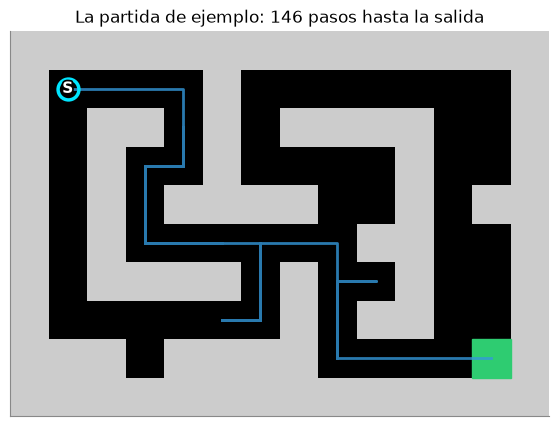

In [9]:
semilla = next(k for k in range(10_000) if caminante(env, 150, semilla=k)[-1] == env.goal)
camino = caminante(env, 150, semilla=semilla)
T = len(camino) - 1                                 # pasos hasta llegar
recompensas = [1.0 if s2 == env.goal else 0.0 for s2 in camino[1:]]
print(f"semilla {semilla}: llega en T = {T} pasos;  recompensas = [0, 0, ..., 0, 1] ({T} números)")
for g in [0, 0.5, 0.9, 0.99, 1.0]:
    print(f"  γ = {g:<4}  G_0 = {retorno(recompensas, g):.4g}    (= γ^(T-1) = {g ** (T - 1):.4g})")

plot_cave(env, path=camino, mark=env.start, title=f"La partida de ejemplo: {T} pasos hasta la salida")
plt.show()

Como el único premio llega en el paso $T$, el retorno es simplemente $\gamma^{T-1}$. Sin descuento ($\gamma = 1$) cualquier partida que llegue vale 1, tarde lo que tarde; con descuento, **llegar tarde cuesta**. Y con $\gamma = 0$ esta partida no vale nada, aunque haya llegado.

## 4. El feed miope contra el de largo plazo (modelo de juguete)

En la clase 1 vimos un feed que ordena publicaciones por el clic de hoy. En el idioma de esta clase, es un sistema con $\gamma \approx 0$: el futuro no pesa. ¿Qué pasa con el usuario a lo largo de muchas sesiones?

> **Modelo de juguete.** Los números son inventados para mostrar la idea; no describen ninguna plataforma real.

### Paso 1 — Un usuario de juguete

El usuario tiene una **satisfacción** oculta, de 0 a 10 (empieza en 5). Cada día el feed le muestra contenido de uno de dos tipos:

- **gancho** (*clickbait*): 6 clics por día, pero la satisfacción baja un nivel (con probabilidad 60 %);
- **útil** (lo que coincide con sus intereses): 3 clics por día, pero la satisfacción sube un nivel (con probabilidad 60 %).

Si vuelve mañana depende de la satisfacción. Con una **regla fija** («siempre gancho» o «siempre útil») el usuario es otra cadena de Markov con recompensa: estados = satisfacción más «se fue» (absorbente), recompensa = clics del día. Nadie decide día a día.

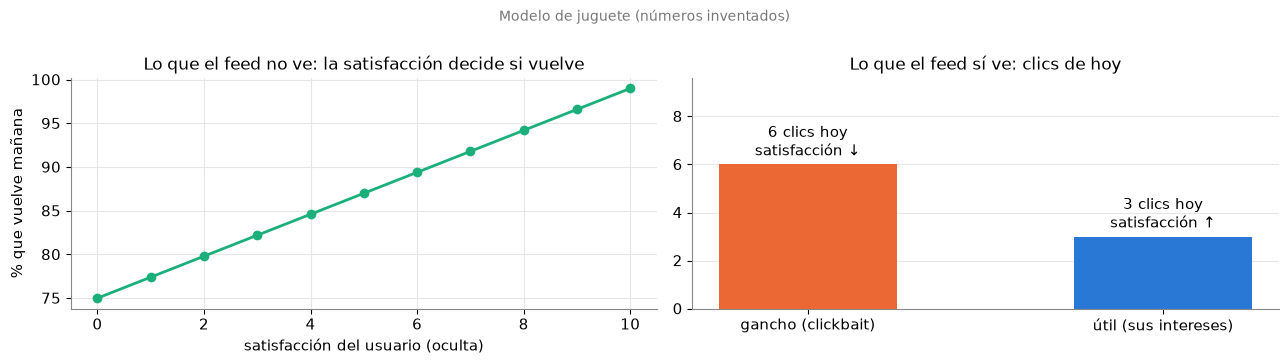

In [10]:
mostrar_usuario()

### Paso 2 — Lo que le pasa al usuario con cada regla

Simulamos 5000 usuarios durante 90 días con cada regla y miramos tres cosas: clics por día, cuántos siguen volviendo y los clics acumulados.

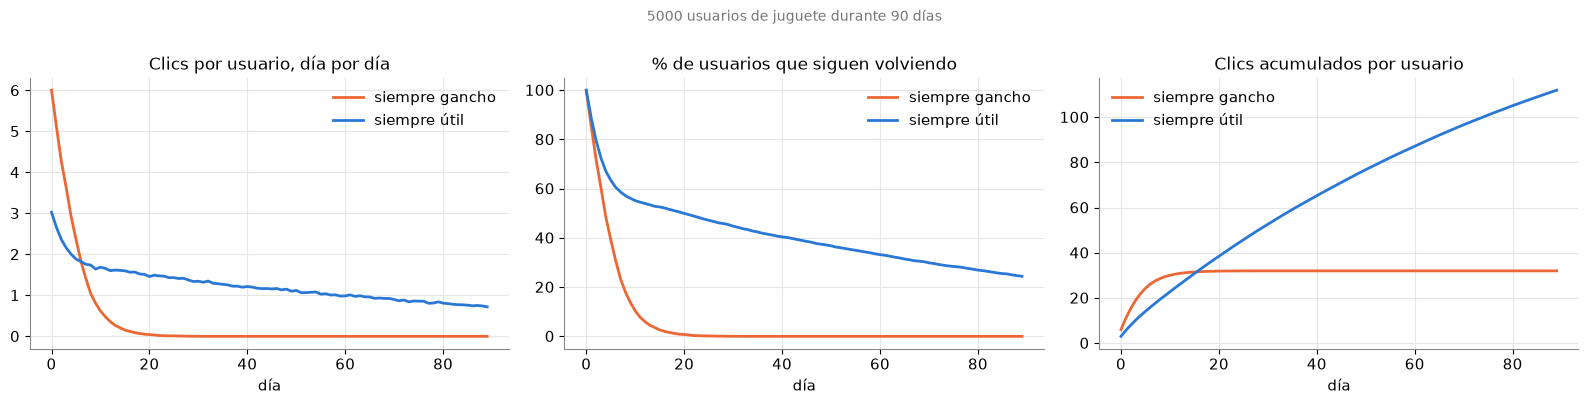

siempre gancho  clics día 1: 6.01 · activos el día 30:   0.0 % · clics en 90 días:   32.0
siempre útil    clics día 1: 3.03 · activos el día 30:  44.8 % · clics en 90 días:  112.0
Los clics acumulados de 'útil' pasan a los de 'gancho' el día 17.


In [11]:
res_feed = comparar_reglas(dias=90)

«Siempre gancho» gana el primer día (el doble de clics), pero vacía el feed. «Siempre útil» junta la mitad por día y conserva a la gente, así que a la larga suma mucho más. Cuál conviene **depende de cuánto pese el futuro**.

### Paso 3 — El feed con $\gamma$

Un feed con descuento $\gamma$ calcula el retorno esperado de cada regla, $G = \sum_t \gamma^t\, \mathbb{E}[\text{clics}_t]$, y se queda con la mayor. (Los clics esperados de cada día salen de empujar la nube de usuarios con $p_{t+1} = p_t P$, como en la sección 1.) Cambien `GAMMA_FEED` y vuelvan a ejecutar.

γ = 0     G(gancho) =    6.00   G(útil) =    3.00   -> el feed elige: gancho


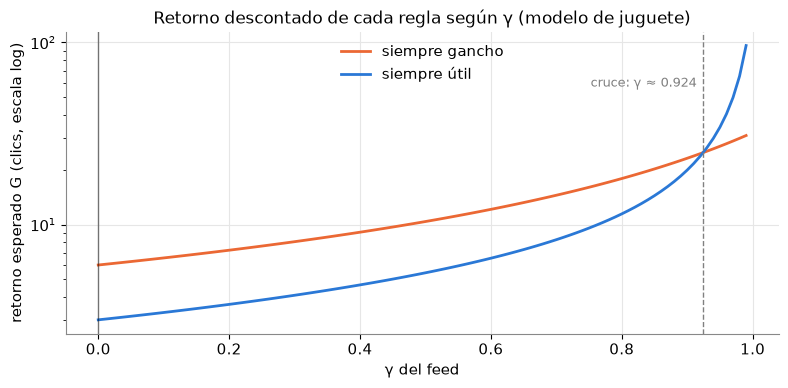


Cruce: con γ mayor que 0.924 el feed elige 'útil'.

γ = 0     G(gancho) =    6.00   G(útil) =    3.00   -> el feed elige: gancho
γ = 0.5   G(gancho) =   10.39   G(útil) =    5.44   -> el feed elige: gancho
γ = 0.8   G(gancho) =   17.90   G(útil) =   11.45   -> el feed elige: gancho
γ = 0.9   G(gancho) =   23.13   G(útil) =   19.92   -> el feed elige: gancho
γ = 0.95  G(gancho) =   26.91   G(útil) =   34.24   -> el feed elige: útil
γ = 0.99  G(gancho) =   30.83   G(útil) =   96.11   -> el feed elige: útil


In [12]:
GAMMA_FEED = 0.0     # probá 0.5, 0.8, 0.9, 0.99

feed_con_gamma(GAMMA_FEED)
cruce_feed = retorno_vs_gamma(gamma_marcado=GAMMA_FEED)
print(f"\nCruce: con γ mayor que {cruce_feed:.3f} el feed elige 'útil'.\n")
for g in [0, 0.5, 0.8, 0.9, 0.95, 0.99]:
    feed_con_gamma(g)

Con $\gamma = 0$ el feed solo ve los clics de hoy y elige **gancho**: es el feed miope. A partir del cruce, el futuro pesa lo suficiente para que el usuario que vuelve valga más que el clic de hoy, y el feed elige **útil**. Nada cambió en el usuario ni en los clics: cambió **cuánto pesa el futuro**.

Una aclaración: acá el feed elige una regla fija de una vez. Decidir día a día, según la satisfacción de cada usuario, es un problema con acciones (un MDP): lo vemos en la clase 4.

## 5. El valor como promedio de muchas caminatas

Cada caminata del caminante da un retorno distinto: a veces llega rápido, casi siempre tarda muchísimo. El **valor** (*value*) de una casilla es el retorno que **espera** quien arranca ahí:

$$V(s) = \mathbb{E}\,[\,G_t \mid s_t = s\,]$$

Desde ahora usamos $\gamma = 0{,}99$.

### Paso 1 — Muchas caminatas desde S

Lanzamos 20 000 caminatas desde S y anotamos el retorno de cada una ($\gamma^{T-1}$ si llega en el paso $T$). Cortamos a los 3000 pasos: lo que llegue después pesaría menos de $0{,}99^{3000} \approx 10^{-13}$.

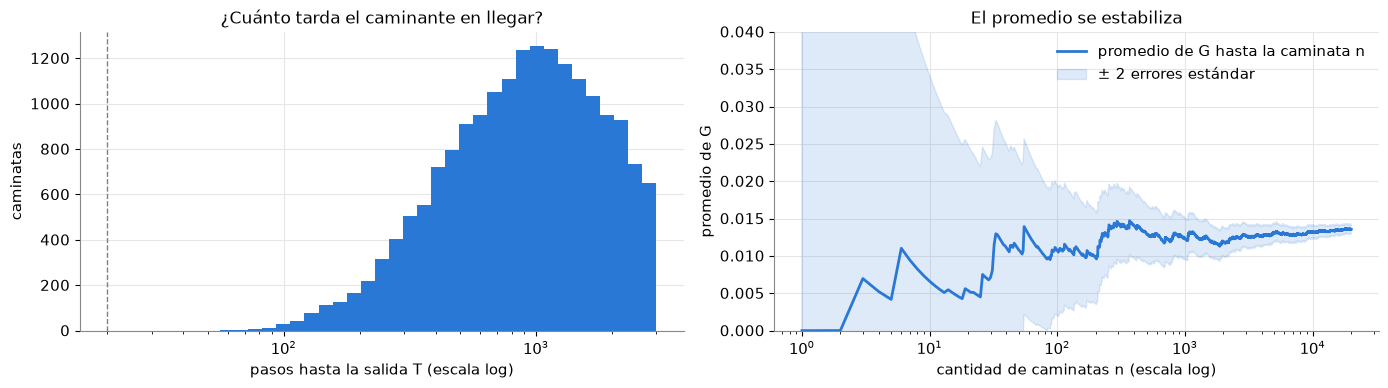

llegaron antes de 3000 pasos: 92.1 %   mediana de T: 931 pasos
V(S) estimado = 0.01357  ± 0.00062  (2 errores estándar, 20000 caminatas, γ = 0.99)


In [13]:
GAMMA = 0.99
N = 20_000
res = caminatas(env, N, GAMMA, semilla=1)
Tc, Gc = res["T"], res["G"]
media = np.cumsum(Gc) / np.arange(1, N + 1)
ee = Gc.std() / np.sqrt(N)                      # error estándar del promedio
V_mc = Gc.mean()

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
llegaron = Tc[Tc > 0]
axs[0].hist(llegaron, bins=np.logspace(np.log10(20), np.log10(3000), 40), color=COLORES[0])
axs[0].set_xscale("log"); axs[0].axvline(20, color="gray", ls="--", lw=1)
axs[0].set_xlabel("pasos hasta la salida T (escala log)"); axs[0].set_ylabel("caminatas")
axs[0].set_title("¿Cuánto tarda el caminante en llegar?")
n = np.arange(1, N + 1)
axs[1].plot(n, media, color=COLORES[0], label="promedio de G hasta la caminata n")
axs[1].fill_between(n, media - 2 * Gc.std() / np.sqrt(n), media + 2 * Gc.std() / np.sqrt(n),
                    color=COLORES[0], alpha=0.15, label="± 2 errores estándar")
axs[1].set_xscale("log"); axs[1].set_ylim(0, 0.04)
axs[1].set_xlabel("cantidad de caminatas n (escala log)"); axs[1].set_ylabel("promedio de G")
axs[1].set_title("El promedio se estabiliza"); axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()

print(f"llegaron antes de 3000 pasos: {100 * np.mean(Tc > 0):.1f} %   mediana de T: {np.median(llegaron):.0f} pasos")
print(f"V(S) estimado = {V_mc:.5f}  ± {2 * ee:.5f}  (2 errores estándar, {N} caminatas, γ = {GAMMA})")

Los retornos de cada caminata son muy distintos, pero **el promedio se estabiliza**: eso es $V(S)$. Es chico porque el premio está lejos y el caminante, sin memoria, tarda mucho en encontrarlo.

### Paso 2 — El valor es de la casilla, no del camino

Si el proceso es de Markov, lo que pasa después de pisar una casilla no depende de cómo se llegó a ella. Lo comprobamos con el cruce (5, 6) de la sección 1, de dos maneras:

1. lanzando caminatas **que arrancan** en el cruce;
2. tomando las caminatas de antes que salieron de S y **pasaron** por el cruce, y mirando su retorno desde ese momento.

In [14]:
desde_cruce = caminatas(env, N, GAMMA, inicio=cruce, semilla=2)
pasan = caminatas(env, N, GAMMA, marca=cruce, semilla=1)          # las mismas caminatas desde S
ok = (pasan["t_marca"] >= 0) & (pasan["T"] > 0)
G_cola = GAMMA ** (pasan["T"][ok] - pasan["t_marca"][ok] - 1.0)
G_cola = np.concatenate([G_cola, np.zeros(np.sum((pasan["t_marca"] >= 0) & (pasan["T"] < 0)))])

for nombre, g in [("arrancando en el cruce", desde_cruce["G"]), ("pasando por el cruce desde S", G_cola)]:
    print(f"V(cruce) {nombre:30s} = {g.mean():.4f} ± {2 * g.std() / np.sqrt(len(g)):.4f}   ({len(g)} caminatas)")

V(cruce) arrancando en el cruce         = 0.0764 ± 0.0023   (20000 caminatas)
V(cruce) pasando por el cruce desde S   = 0.0777 ± 0.0023   (19999 caminatas)


Las dos estimaciones coinciden dentro del error de muestreo: el retorno que se espera desde el cruce no se acuerda de dónde venía el caminante. Por eso el valor se puede escribir como una función de la casilla, $V(s)$. (Estimar $V$ promediando partidas, sin conocer $P$, es el método de **Monte Carlo** de la clase 5.)

## 6. Bellman: $V = R + \gamma P V$ y la solución directa

Promediar miles de caminatas funciona, pero hay un atajo. Partamos el retorno en «lo de ahora» y «todo lo demás»: $G_t = r_t + \gamma\, G_{t+1}$. Tomando el promedio, el valor de una casilla es el premio esperado ahora más $\gamma$ por el valor promedio de adonde voy a parar:

$$V(s) = R(s) + \gamma \sum_{s'} P[s, s']\, V(s') \qquad\text{o, para todas las casillas a la vez,}\qquad V = R + \gamma P V$$

Es la **ecuación de Bellman** de un MRP. Son 60 ecuaciones lineales con 60 incógnitas. En la nivelación 0c lo resolvimos de un saque: $V = (I - \gamma P)^{-1} R$ (con `np.linalg.solve`).

### Paso 1 — La solución directa

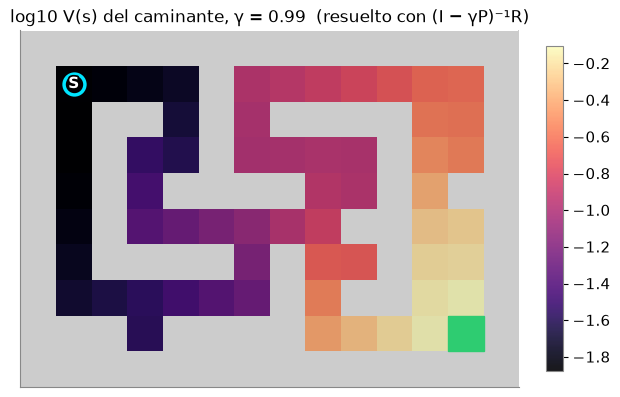

V(S) directo  = 0.01359     V(cruce) directo = 0.0771
V(salida)     = 0  (terminal: ya no queda nada por cobrar)
vecinas de la salida: V(7, 12) = 0.786, V(8, 11) = 0.773
mínimo de V: 0.01321 en la casilla (2, 1)


In [15]:
V = np.linalg.solve(np.eye(env.nS) - GAMMA * P, R)
plot_cave(env, values=log10_seguro(V), mark=env.start,
          title=f"log10 V(s) del caminante, γ = {GAMMA}  (resuelto con (I − γP)⁻¹R)")
plt.show()
print(f"V(S) directo  = {V[env.start]:.5f}     V(cruce) directo = {V[cruce]:.4f}")
print(f"V(salida)     = {V[env.goal]:.0f}  (terminal: ya no queda nada por cobrar)")
print(f"vecinas de la salida: " + ", ".join(f"V{env.free[s]} = {V[s]:.3f}" for s in np.flatnonzero(R)))
otras = np.arange(env.nS) != env.goal
print(f"mínimo de V: {V[otras].min():.5f} en la casilla {env.free[int(np.argmin(np.where(otras, V, np.inf)))]}")

El valor es mayor cerca de la salida y cae hacia el fondo de la cueva (por eso lo pintamos en escala logarítmica).

### Paso 2 — La ecuación, casilla por casilla

Comprobemos la ecuación en S: premio ahora + $\gamma$ · (promedio del valor de adonde puede ir, pesado con su fila de $P$).

In [16]:
s = env.start
print(f"V(S) = R(S) + γ · Σ P[S, s'] V(s')")
print(f"     = {R[s]:.0f} + {GAMMA} · (" +
      " + ".join(f"{P[s, s2]:.2f}·{V[s2]:.5f}" for s2 in np.flatnonzero(P[s])) + ")")
print(f"     = {R[s] + GAMMA * P[s] @ V:.5f}     y V(S) = {V[s]:.5f}")
print(f"\nEn todas las casillas: max |V − (R + γPV)| = {np.max(np.abs(V - (R + GAMMA * P @ V))):.1e}")

V(S) = R(S) + γ · Σ P[S, s'] V(s')
     = 0 + 0.99 · (0.50·0.01359 + 0.25·0.01452 + 0.25·0.01321)
     = 0.01359     y V(S) = 0.01359

En todas las casillas: max |V − (R + γPV)| = 2.2e-16


### Paso 3 — ¿Coincide con el promedio de caminatas?

La solución directa no tiró ningún dado; el promedio de la sección 5 no usó la ecuación. Si las dos cosas hablan del mismo $V$, tienen que coincidir dentro del error de muestreo.

In [17]:
for nombre, s_, g in [("S", env.start, Gc), ("cruce", cruce, desde_cruce["G"])]:
    e2 = 2 * g.std() / np.sqrt(len(g))
    dentro = abs(g.mean() - V[s_]) <= e2
    print(f"V({nombre}):  caminatas = {g.mean():.5f} ± {e2:.5f}   directo = {V[s_]:.5f}   "
          f"¿dentro del error? {'sí' if dentro else 'no'}")

V(S):  caminatas = 0.01357 ± 0.00062   directo = 0.01359   ¿dentro del error? sí
V(cruce):  caminatas = 0.07643 ± 0.00227   directo = 0.07708   ¿dentro del error? sí


## 7. Iterar desde $V = 0$: el valor se derrama

Otra manera de resolver $V = R + \gamma P V$, sin invertir nada: arrancar con $V_0 = 0$ y usar la ecuación como **regla de actualización**, una y otra vez:

$$V_{k+1} = R + \gamma P V_k$$

Cada vuelta mira un paso más hacia adelante. Pintamos $\log_{10} V_k$ en algunas vueltas, todas con la misma escala (negro = todavía 0; el círculo marca S).

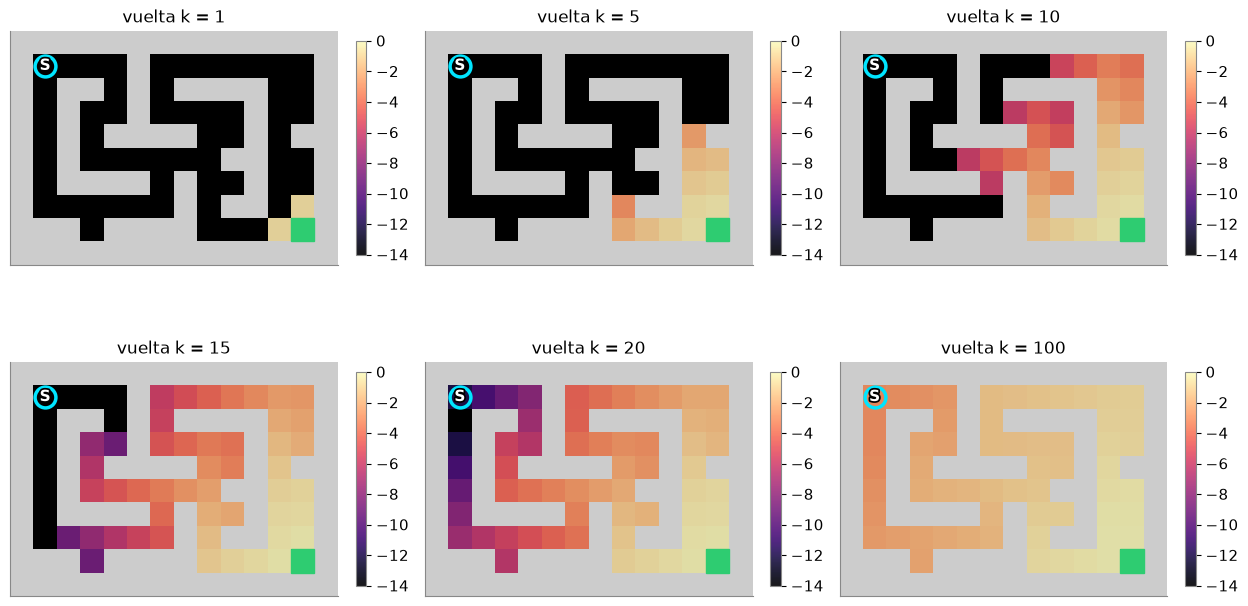

In [18]:
hist = iterar(P, R, GAMMA, tol=1e-12)
vueltas = len(hist) - 1
ks = [1, 5, 10, 15, 20, 100]
plot_row(env, [log10_seguro(hist[k], piso=0) for k in ks], [f"vuelta k = {k}" for k in ks],
         clim=(-14, 0), size=4.2, ncols=3, marks=[env.start] * len(ks))

El valor **nace al lado de la salida y se derrama hacia atrás, una casilla por vuelta**: en la vuelta $k$ tienen valor exactamente las casillas que están a $k$ pasos o menos de la salida. Midámoslo: cuántas casillas tienen valor en cada vuelta, en qué vuelta le llega algo a S y cómo crece $V_k(S)$ hasta el valor de la solución directa.

¿En cada vuelta k (1 a 60) tienen valor justo las casillas a k pasos o menos de la salida? sí
S está a 20 pasos; la casilla más lejana, [(2, 1)], a 21.


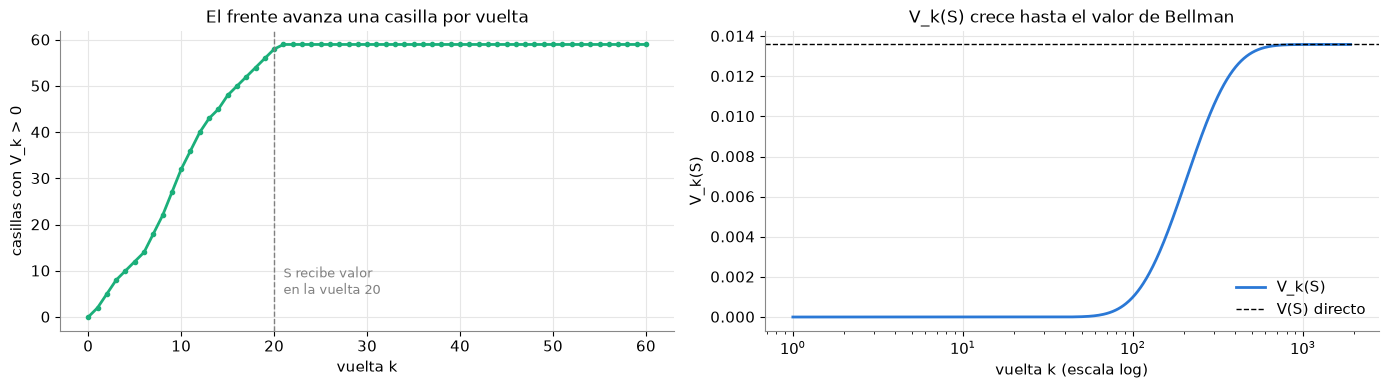

V_19(S) = 0
V_20(S) = 7.51e-13
V_21(S) = 7.45e-12
V_100(S) = 0.000997
V_500(S) = 0.0132
V_1000(S) = 0.0136

Convergió (cambio máximo < 1e-12) en 1906 vueltas.
max |V_iterado − V_directo| = 9.0e-11


In [19]:
H = np.array(hist)
con_valor = (H > 0).sum(axis=1)
k_llega = int(np.argmax(H[:, env.start] > 0))
d = distancias(env)
lejos = np.flatnonzero(d == d.max())
print("¿En cada vuelta k (1 a 60) tienen valor justo las casillas a k pasos o menos de la salida?",
      "sí" if all(np.array_equal(H[k] > 0, (d <= k) & (d > 0)) for k in range(1, 61)) else "no")
print(f"S está a {d[env.start]} pasos; la casilla más lejana, {[env.free[s] for s in lejos]}, a {d.max()}.")

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(range(61), con_valor[:61], "o-", ms=3, color=COLORES[2])
axs[0].axvline(k_llega, color="gray", ls="--", lw=1)
axs[0].text(k_llega + 1, 5, f"S recibe valor\nen la vuelta {k_llega}", color="gray", fontsize=9)
axs[0].set_xlabel("vuelta k"); axs[0].set_ylabel("casillas con V_k > 0")
axs[0].set_title("El frente avanza una casilla por vuelta")
kk = np.arange(1, len(H))
axs[1].semilogx(kk, H[1:, env.start], color=COLORES[0], label="V_k(S)")
axs[1].axhline(V[env.start], color="k", ls="--", lw=1, label="V(S) directo")
axs[1].set_xlabel("vuelta k (escala log)"); axs[1].set_ylabel("V_k(S)")
axs[1].set_title("V_k(S) crece hasta el valor de Bellman"); axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()

for k in [19, 20, 21, 100, 500, 1000]:
    print(f"V_{k}(S) = {H[k, env.start]:.3g}")
print(f"\nConvergió (cambio máximo < 1e-12) en {vueltas} vueltas.")
print(f"max |V_iterado − V_directo| = {np.max(np.abs(H[-1] - V)):.1e}")

S está a 20 pasos de la salida y recibe su primer valor en la vuelta 20, tan chico ($\approx 10^{-12}$) que en el mapa apenas se distingue del negro. La última casilla en recibir valor es la de abajo de S, a 21 pasos (para llegar tiene que pasar por S). Después tarda cientos de vueltas en llenarse: cada vuelta suma caminos un paso más largos, y el caminante usa muchos caminos largos.

### Los tres caminos, el mismo número

El promedio de caminatas, la solución directa y la iteración tratan la salida igual (al llegar se cobra +1 y no se cobra nada más), así que tienen que dar el mismo $V(S)$:

In [20]:
print(f"V(S), γ = {GAMMA}")
print(f"  promedio de {N} caminatas : {V_mc:.5f} ± {2 * ee:.5f}")
print(f"  solución directa           : {V[env.start]:.5f}")
print(f"  iteración desde V = 0      : {H[-1, env.start]:.5f}   ({vueltas} vueltas)")

V(S), γ = 0.99
  promedio de 20000 caminatas : 0.01357 ± 0.00062
  solución directa           : 0.01359
  iteración desde V = 0      : 0.01359   (1906 vueltas)


## ✍️ Ejercicio — Cambien $\gamma$ y miren cómo cambia $V(S)$

Cambien `gamma_ej` (prueben 0.5, 0.9, 0.999) y ejecuten. La celda calcula $V(S)$ con la solución directa y con la iteración desde $V = 0$, y les dice en qué vuelta le llega valor a S y cuántas vueltas hacen falta para converger.

Preguntas: ¿cuánto vale S con $\gamma = 0{,}5$? ¿Cambia la vuelta en que le llega valor a S? ¿Y la cantidad de vueltas para converger? Comparen $V(S)$ con $\gamma^{19}$, el valor de una partida que va derecho a la salida.

γ = 0.9:  V(S) directo = 1.07e-06   iterado = 1.07e-06
   le llega valor a S en la vuelta 20;  converge en 203 vueltas
   γ^19 (ir derecho) = 0.135


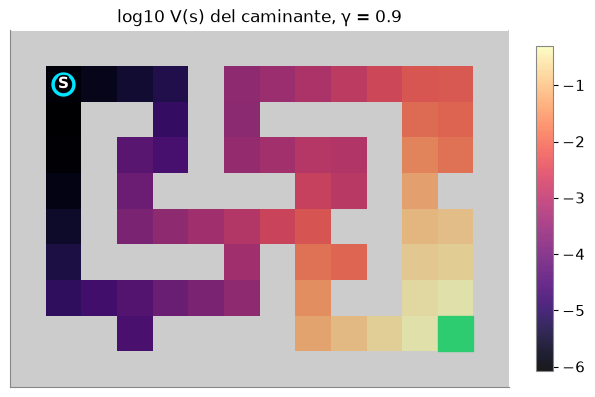

In [21]:
gamma_ej = 0.9   # TODO: probá 0.5, 0.9, 0.999

V_ej = np.linalg.solve(np.eye(env.nS) - gamma_ej * P, R)
h_ej = np.array(iterar(P, R, gamma_ej, tol=1e-12))
print(f"γ = {gamma_ej}:  V(S) directo = {V_ej[env.start]:.3g}   iterado = {h_ej[-1, env.start]:.3g}")
print(f"   le llega valor a S en la vuelta {int(np.argmax(h_ej[:, env.start] > 0))};  converge en {len(h_ej) - 1} vueltas")
print(f"   γ^19 (ir derecho) = {gamma_ej ** 19:.3g}")
plot_cave(env, values=log10_seguro(V_ej), mark=env.start, title=f"log10 V(s) del caminante, γ = {gamma_ej}")
plt.show()

## Preguntas para pensar

1. En la sección 7 el valor llega a S en la vuelta 20 sea cual sea $\gamma$. ¿Por qué? ¿Qué es lo que sí cambia con $\gamma$?
2. En el feed de juguete, ¿quién elige el $\gamma$? ¿Qué $\gamma$ elegirían ustedes para un feed, y cómo lo justificarían ante el usuario?
3. Hoy el caminante tiraba un dado. Si pudiera elegir la dirección en cada casilla, ¿cómo usarían el mapa de $V$ para elegir?

## Próxima clase

El caminante no elige. Si pudiera elegir, tendríamos un **proceso de decisión de Markov** (*Markov decision process*, MDP) = cadena + acciones. En la clase 4 **planificamos con mapa**: la misma ecuación de Bellman, pero quedándonos con la mejor acción en cada casilla (iteración de valor y de política).